In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import tensorflow as tf
import os

Let us first load the dataset set by reading the train, val and test directories. We will use the tf.keras.utils.image_dataset_from_directory to do this.

In [2]:
base = os.getcwd()

In [3]:
train_dir = os.path.join(base,'Train')
test_dir = os.path.join(base,'Test')
val_dir = os.path.join(base,'Validation')
train_data = tf.keras.utils.image_dataset_from_directory(train_dir, labels='inferred', label_mode='categorical', 
                                                         class_names = ['Healthy', 'Powdery', 'Rust'], batch_size = 32, 
                                                         image_size = (256, 256), shuffle = True, seed = 123, 
                                                         validation_split = 0)
test_data = tf.keras.utils.image_dataset_from_directory(test_dir, labels='inferred', label_mode='categorical', 
                                                         class_names = ['Healthy', 'Powdery', 'Rust'], batch_size = 32, 
                                                         image_size = (256, 256), shuffle = True, seed = 123, 
                                                         validation_split = 0)
validation_data = tf.keras.utils.image_dataset_from_directory(val_dir, labels='inferred', label_mode='categorical', 
                                                         class_names = ['Healthy', 'Powdery', 'Rust'], batch_size = 32, 
                                                         image_size = (256, 256), shuffle = True, seed = 123, 
                                                         validation_split = 0)

Found 1322 files belonging to 3 classes.
Found 150 files belonging to 3 classes.
Found 60 files belonging to 3 classes.


In [4]:
class_labels = train_data.class_names
class_labels

['Healthy', 'Powdery', 'Rust']

(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)


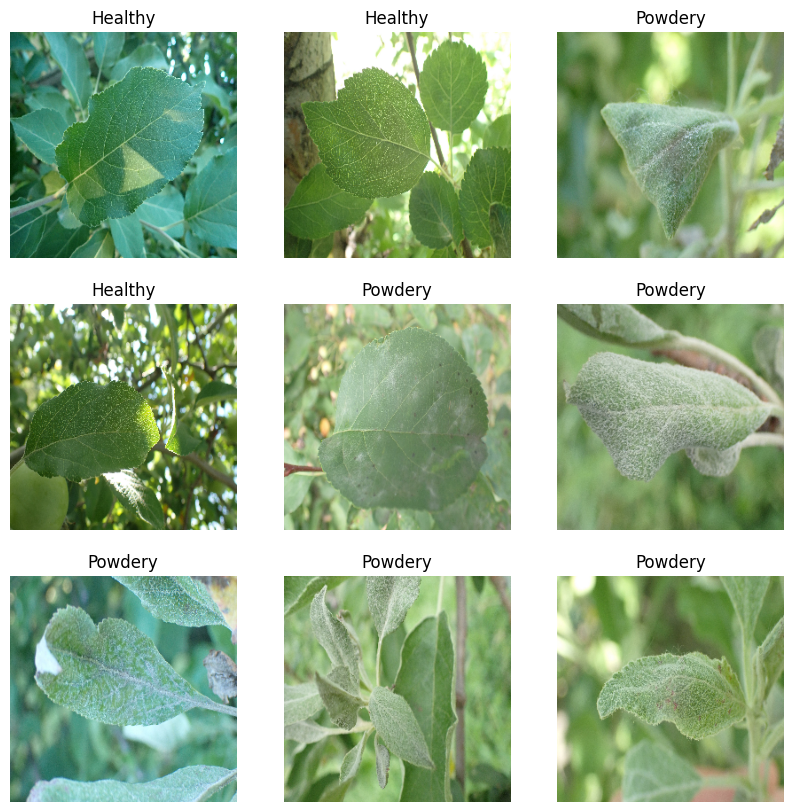

In [6]:
fig = plt.figure(figsize=(10,10))
for image_batch , image_label in train_data.take(3):
#     print(np.array(image_batch)
    for i in range(9):
        plt.subplot(3,3,i+1)
        print(image_batch[i].numpy().shape)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_labels[np.argmax(image_label[i])])
        plt.axis("off")
plt.show()
fig.clear()

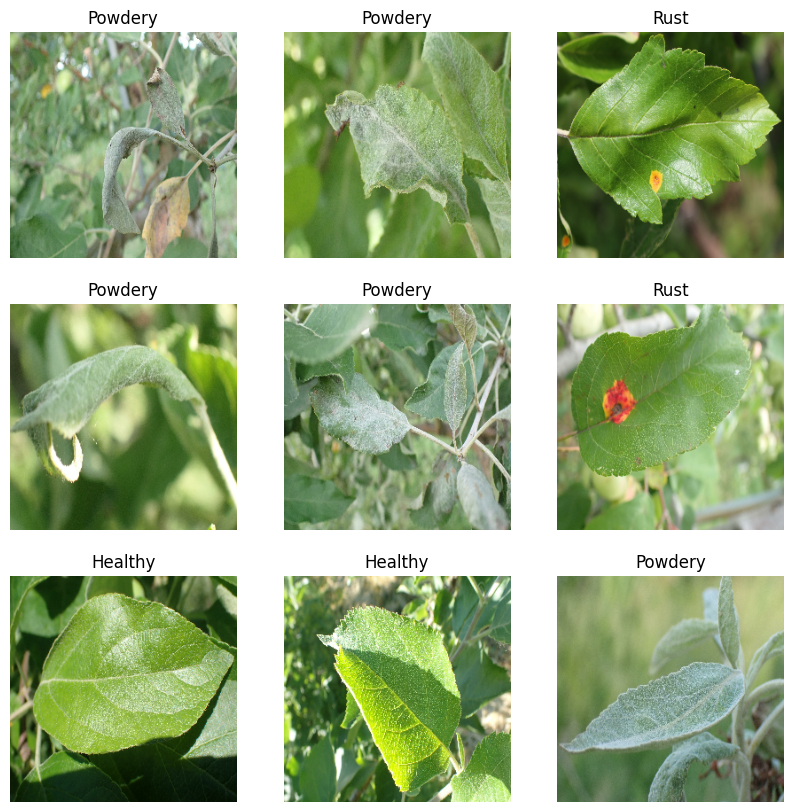

In [10]:
fig = plt.figure(figsize=(10,10))
for image_batch , image_label in test_data.take(1):
#     print(np.array(image_batch)
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_labels[np.argmax(image_label[i])])
        plt.axis("off")
plt.show()
fig.clear()

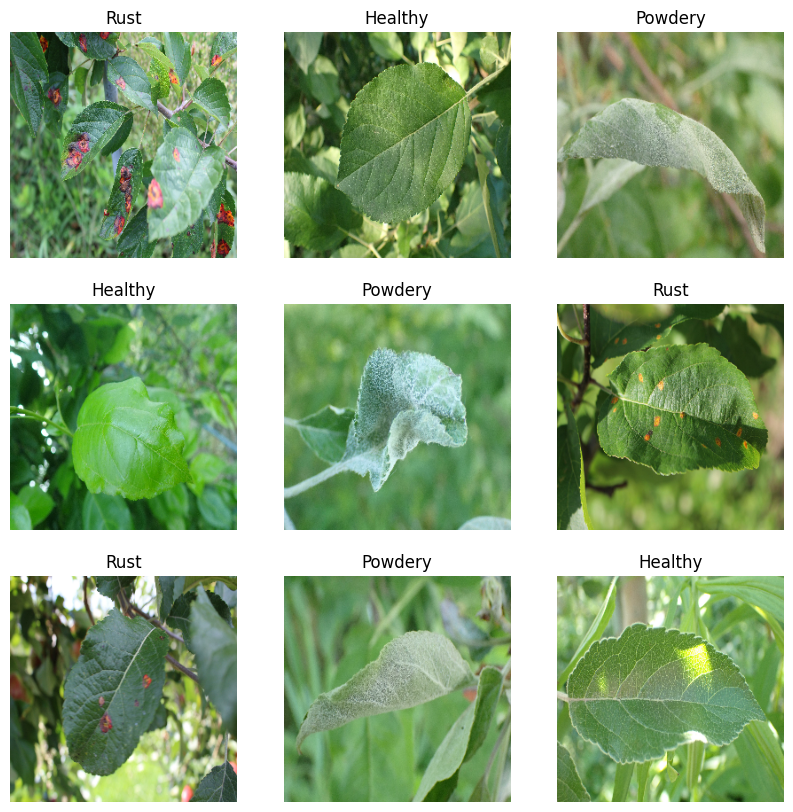

In [29]:
fig = plt.figure(figsize=(10,10))
for image_batch , image_label in validation_data.take(1):
#     print(np.array(image_batch)
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_labels[np.argmax(image_label[i])])
        plt.axis("off")
plt.show()
fig.clear()

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D, BatchNormalization, Input, Rescaling, Flatten

In [6]:
scaler = Rescaling(1./255)
train_data = train_data.map(lambda x, y: (scaler(x), y)) 
test_data = test_data.map(lambda x, y: (scaler(x), y))
validation_data = validation_data.map(lambda x, y: (scaler(x), y))

In [7]:
# Checking minimum and maximum pixel values in the dataset
min_value = np.min(validation_data.as_numpy_iterator().next()[0])
max_value = np.max(validation_data.as_numpy_iterator().next()[0])
print('\nMinimum pixel value in the Validation dataset', min_value)
print('\nMaximum pixel value in the Validation dataset', max_value)


Minimum pixel value in the Validation dataset 0.0

Maximum pixel value in the Validation dataset 1.0


In [39]:
model = Sequential([Input(shape=(256,256,3))])

model.add(Conv2D(16, kernel_size = 3, padding='same', activation='relu'))
model.add(MaxPool2D(pool_size=(2,2)))
model.add(Conv2D(16, kernel_size = 3, padding='same', activation='relu'))
model.add(MaxPool2D(pool_size=(2,2)))
# model.add(BatchNormalization())
model.add(Dropout(0.4))

model.add(Conv2D(32, kernel_size = 3, activation='relu'))
model.add(MaxPool2D(pool_size=(2,2)))
model.add(Conv2D(32, kernel_size = 3, activation='relu'))
model.add(MaxPool2D(pool_size=(2,2)))
# model.add(BatchNormalization())
model.add(Dropout(0.4))

model.add(Flatten())
model.add(Dense(3, activation='softmax'))

# COMPILE WITH ADAM OPTIMIZER AND CROSS ENTROPY COST
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)                    │ (None, 256, 256, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 128, 128, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 128, 128, 16)        │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 62, 62, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 29, 29, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 6272)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │          18,819 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 35,475 (138.57 KB)

 Trainable params: 35,475 (138.57 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
history = model.fit(train_data,
                    validation_data=validation_data, 
                    epochs=20, 
                    verbose=1)

Epoch 1/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.4330 - loss: 1.0241 - val_accuracy: 0.5333 - val_loss: 0.7930
Epoch 2/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.7532 - loss: 0.5985 - val_accuracy: 0.6333 - val_loss: 0.7363
Epoch 3/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.7600 - loss: 0.5484 - val_accuracy: 0.5000 - val_loss: 0.9091
Epoch 4/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.7354 - loss: 0.5858 - val_accuracy: 0.5667 - val_loss: 0.7202
Epoch 5/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.7913 - loss: 0.5033 - val_accuracy: 0.6167 - val_loss: 0.7233
Epoch 6/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.7887 - loss: 0.4835 - val_accuracy: 0.6167 - val_loss: 0.7037
Epoch 7/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.8125 - loss: 0.4531 - val_accuracy: 0.7333 - val_loss: 0.6200
Epoch 8/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8715 - loss: 0.3507 - val_accuracy: 0.8000 - val_loss:

In [52]:
model.save('4_layer_CNN_Plant_disease_recognition.h5')

In [8]:
#Loading the model again
model = tf.keras.models.load_model('4_layer_CNN_Plant_disease_recognition.h5')
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)                    │ (None, 256, 256, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 128, 128, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 128, 128, 16)        │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 62, 62, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 29, 29, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 6272)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │          18,819 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 35,477 (138.59 KB)

 Trainable params: 35,475 (138.57 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [9]:
loss,acc = model.evaluate(train_data)
print("Loss on Train data:",loss)
print("Accuracy on Train data:",acc)

loss1,acc1 = model.evaluate(test_data)

print("Loss on Test data:",loss1)
print("Accuracy on Test data:",acc1)

42/42 ━━━━━━━━━━━━━━━━━━━━ 21s 479ms/step - accuracy: 0.9881 - loss: 0.0608
Loss on Train data: 0.05528320372104645
Accuracy on Train data: 0.9894099831581116
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 428ms/step - accuracy: 0.9296 - loss: 0.2460
Loss on Test data: 0.2295716404914856
Accuracy on Test data: 0.9333333373069763


In [19]:
test_pred = model.predict(test_data)

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 442ms/step


In [24]:
# print(test_pred)
test_pred_labels = np.argmax(test_pred, axis=1)
test_pred_labels

array([1, 1, 1, 0, 0, 1, 1, 0, 1, 2, 0, 1, 2, 1, 1, 2, 1, 2, 0, 2, 1, 1,
       0, 2, 1, 1, 0, 1, 1, 1, 2, 1, 0, 0, 2, 2, 0, 1, 2, 0, 2, 2, 0, 2,
       0, 1, 0, 0, 2, 1, 2, 1, 0, 1, 1, 2, 1, 0, 0, 1, 1, 2, 1, 2, 0, 1,
       1, 2, 0, 1, 2, 2, 2, 0, 2, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 2, 0, 2,
       1, 2, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 2, 0, 2, 2, 1, 2, 0, 0, 2,
       1, 2, 1, 1, 0, 1, 2, 2, 0, 0, 1, 0, 2, 2, 0, 1, 0, 2, 0, 1, 0, 1,
       0, 0, 2, 0, 0, 1, 0, 2, 2, 2, 0, 0, 2, 0, 1, 2, 2, 2], dtype=int64)

In [33]:
model.history.history

{}

In [37]:
def Prediction(model,img):
    img_array = tf.keras.preprocessing.image.img_to_array((images[i].numpy()))
    img_array = tf.expand_dims(img_array,0)     # create a batch, as the input is expected as a batch

    predictions = model.predict(img_array)

    predicted_class = class_labels[np.argmax(predictions[0])]
    confidence = round(100*(np.max(predictions[0])),2)
    
    return predicted_class , confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━

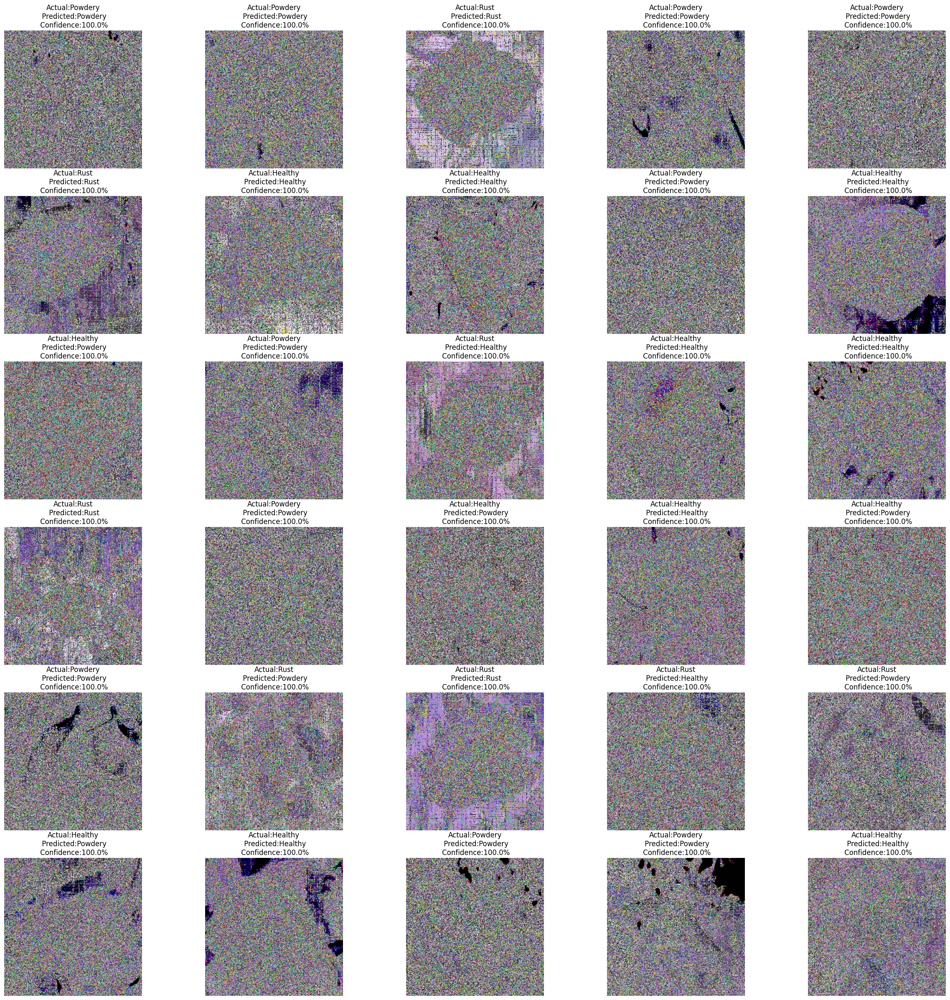

In [48]:
scaler = Rescaling(255)
test_data = test_data.map(lambda x, y: (scaler(x), y))
plt.figure(figsize=(30,30))
for images , labels in test_data.take(1):
#     print(images)
    for i in range(30):
        ax = plt.subplot(6,5,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        #plt.title(class_labels[labels[i]])


        predicted_class , confidence = Prediction(model,images[i].numpy())
        actual_class = class_labels[np.argmax(labels[i])]
        plt.title(f"Actual:{actual_class}\n Predicted:{predicted_class}\n Confidence:{confidence}%")
        plt.axis("off")